# Choix du modèle

Le modèle que nous avons choisi est Qwen2.5-1.5B-Instruct. <br>
C'est un modèle open source de Alibaba ayant 1,5 milliard de paramètres, il est moins lourd que d'autres modèles conseillés, ce qui nous facilite l'inférence en local sur nos ordinateurs portables de l'école. <br>

Qwen2.5-1.5B-Instruct est un petit modèle de type Transformer decoder, conçu pour le dialogue et le suivi d'instructions, il a aussi des capacités adaptées à la génération en français. <br>

Par rapport à la version de base, la version Instruct a subi du post-training notamment pour améliore le suivi d'instructions et le role-play/condition-setting.

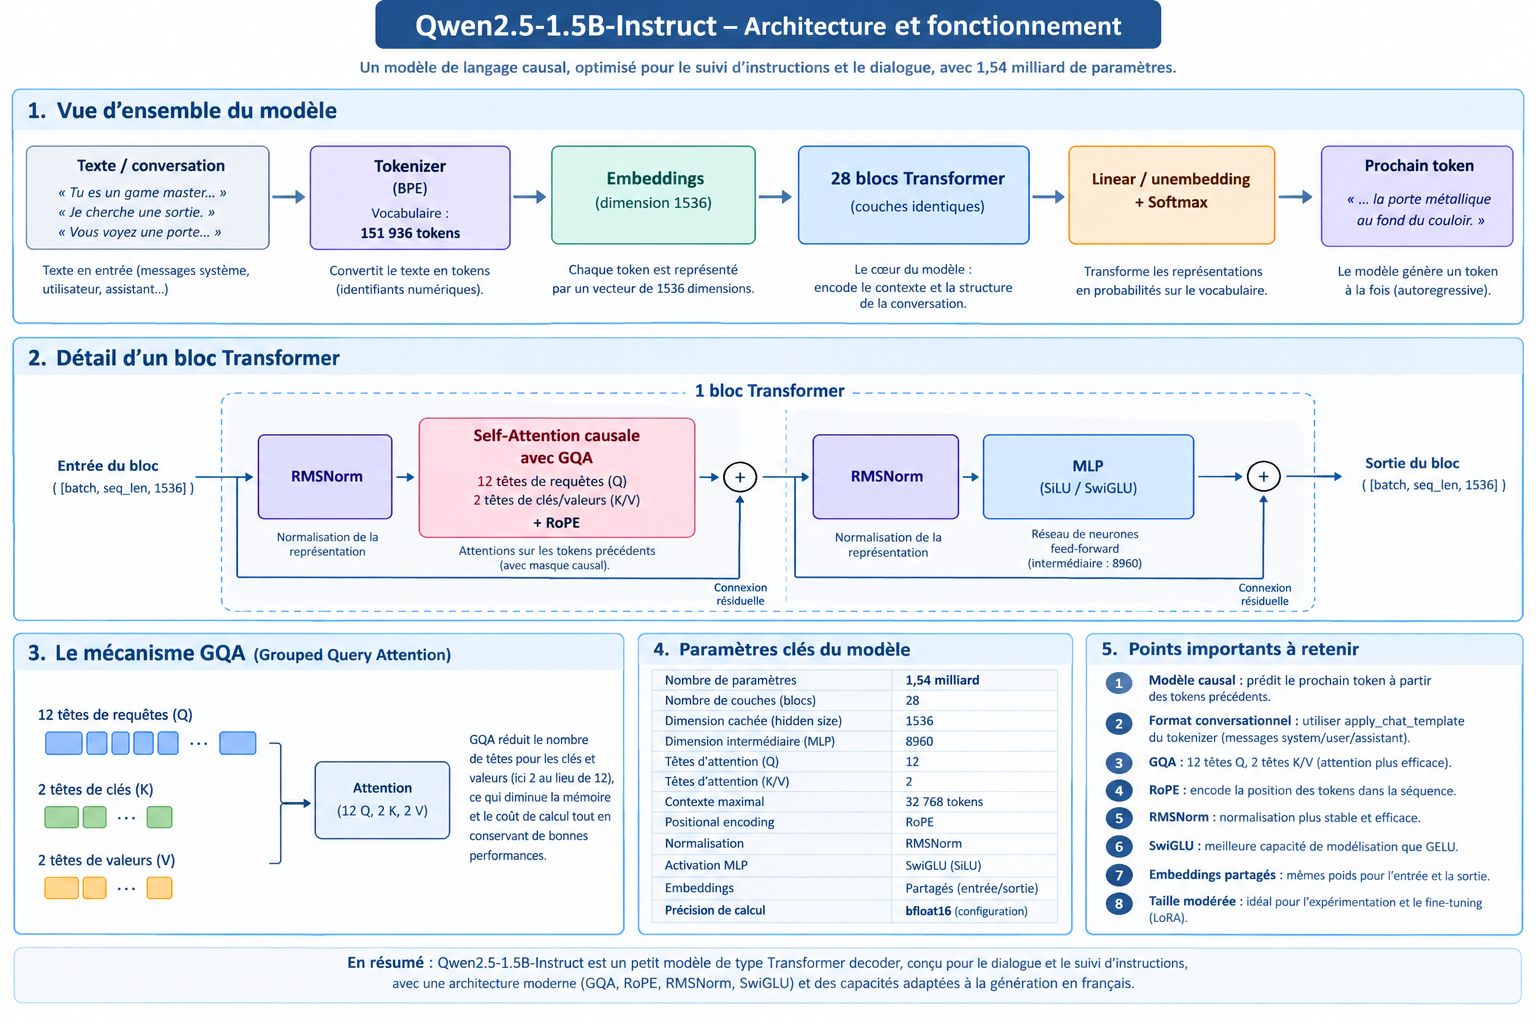

# Chargement du modèle et du tokenizer

In [25]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)
tokenizer = AutoTokenizer.from_pretrained(model_name)

Loading weights: 100%|██████████| 338/338 [00:03<00:00, 97.58it/s]


Exemple simple

In [26]:
prompt = "Je regarde autour de moi."
messages = [
    {
        "role": "system",
        "content": "Tu es le Game Master d'un jeu narratif."
    },
    {
        "role": "user",
        "content": prompt
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)
inputs = tokenizer([text], return_tensors="pt").to(model.device)

generated_ids = model.generate(
    **inputs,
    max_new_tokens=150
)
generated_ids = [
    output_ids[len(input_ids):] for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
]

response = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0]

print(response)

Il semble que vous soyez dans un petit village en plein cœur des montagnes. Le ciel est bleu et les monts sont loin à l'horizon. Vous pouvez entendre la voix douce du vent qui murmure entre les rochers. Les arbres ont des feuilles vert clair, comme si elles étaient pleines de lumière. La nature semble s'y sentir paisible ici.


Pour utiliser le modèle Qwen2.5-1.5B-Instruct, on doit fournir à son tokenizer un chat template spécifique, on doit lui donner un json ou il y a 3 types éléments: <br>
- le role "system" et le content qui correspond au contexte global pour l'agent
- le role "user" et le content qui correspond au prompt de l'utilisateur
- le role "assistant" et le content qui correspond à la réponse de l'agent

Nous devons avoir obligatoirement avoir une élément pour le role "system", puis une alternance de role "user" et "assistant", cela constitue l'historique donné au modèle. <br>

Le message json est transformé en chat template à l'aide de la fonction apply_chat_template du tokenizer, ceci va notamment ajouter des balises <|im_start|> et <|im_end|> pour donner une indication au transformer. 

In [27]:
print(text)

<|im_start|>system
Tu es le Game Master d'un jeu narratif.<|im_end|>
<|im_start|>user
Je regarde autour de moi.<|im_end|>
<|im_start|>assistant



# Identifiants produits par la tokenisation

In [28]:
input_ids = inputs["input_ids"][0]

tokens = tokenizer.convert_ids_to_tokens(input_ids)

for i, (token_id, token) in enumerate(zip(input_ids.tolist(), tokens)):
    print(f"{i:3d} | ID = {token_id:6d} | token = {repr(token)}")

  0 | ID = 151644 | token = '<|im_start|>'
  1 | ID =   8948 | token = 'system'
  2 | ID =    198 | token = 'Ċ'
  3 | ID =  52971 | token = 'Tu'
  4 | ID =   1531 | token = 'Ġes'
  5 | ID =    512 | token = 'Ġle'
  6 | ID =   4050 | token = 'ĠGame'
  7 | ID =  10824 | token = 'ĠMaster'
  8 | ID =    294 | token = 'Ġd'
  9 | ID =  22052 | token = "'un"
 10 | ID =  50555 | token = 'Ġjeu'
 11 | ID =  13408 | token = 'Ġnarr'
 12 | ID =  49748 | token = 'atif'
 13 | ID =     13 | token = '.'
 14 | ID = 151645 | token = '<|im_end|>'
 15 | ID =    198 | token = 'Ċ'
 16 | ID = 151644 | token = '<|im_start|>'
 17 | ID =    872 | token = 'user'
 18 | ID =    198 | token = 'Ċ'
 19 | ID =  29754 | token = 'Je'
 20 | ID =   1217 | token = 'Ġreg'
 21 | ID =  41341 | token = 'arde'
 22 | ID =  88953 | token = 'Ġautour'
 23 | ID =    409 | token = 'Ġde'
 24 | ID =  39991 | token = 'Ġmoi'
 25 | ID =     13 | token = '.'
 26 | ID = 151645 | token = '<|im_end|>'
 27 | ID =    198 | token = 'Ċ'
 28 | ID =

On voit ici que le message entier avec les différents roles et contents sont transformé en token puis en identifiants. <br>

On remarque que les tokens ne sont pas de simples séparations de mots, nous avons par exemple les 20ème et 21ème tokens 'Ġreg' et 'arde' qui proviennent de " regarde". <br>
On devine aussi que le modèle prend en compte la casse puisque tous les tokens ne sont pas uniformisés en majuscule ou miniscule. <br>
Aussi, il y a une différenciation lorsqu'un mot est précédé d'un espace, le token commence par 'Ġ', puis le retour à ligne a aussi son token spécifique 'Ċ'. De même pour les balises '<|im_start|>' et '<|im_end|>'. <br>

Il y a par ailleurs dans le vocabulaire 151936 tokens. 

# Forme des logits retournés par le modèle

In [29]:
model.eval()

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits

print("Shape des logits :", logits.shape)
print(logits)

Shape des logits : torch.Size([1, 31, 151936])
tensor([[[ 6.9375, 11.1875,  8.5000,  ...,  0.1240,  0.1240,  0.1240],
         [ 5.5938,  7.1250,  8.3125,  ...,  0.5898,  0.5898,  0.5898],
         [10.0000, 11.5000, 13.8750,  ..., -2.6406, -2.6406, -2.6406],
         ...,
         [ 1.3984,  2.8906,  0.3086,  ..., -0.2559, -0.2559, -0.2559],
         [ 7.0625, 10.3750,  5.9688,  ..., -1.2344, -1.2344, -1.2344],
         [ 7.3750, 13.0625,  4.3438,  ..., -2.2969, -2.2969, -2.2969]]],
       dtype=torch.bfloat16)


Le logits retourné a pour dimension (B, T, V) = (1, 31, 151936)<br>

B = 1 correspond au nombre de texte que nous donnons au modèle (dans le cas de l'entraînement, il est donc fort proble que B > 1). <br>
T = 31 correspond au nombre de tokens dans le texte, elle peut atteindre jusqu'à 32 768 tokens, c'est le contexte maximal pour ce modèle. <br>
V = 151 936 correspond au nombre de tokens dans le vocabulaire, on nous donne un score pour chacun des tokens possibles. 

# Distribution du prochain token obtenue par softmax

In [30]:
next_token_logits = logits[:, -1, :]

probs = torch.softmax(next_token_logits, dim=-1)

print("Somme des probabilités :", probs.sum().item())
print("Shape :", probs.shape)
print(probs)

Somme des probabilités : 1.0
Shape : torch.Size([1, 151936])
tensor([[5.6624e-07, 1.6689e-04, 2.7241e-08,  ..., 3.5698e-11, 3.5698e-11,
         3.5698e-11]], dtype=torch.bfloat16)


Lors de l'inférence, on ne s'intéresse qu'au dernier token, d'où logits[:, -1, :]. <br>

Après application du softmax, on obtient la distribution du prochain token, la somme donne 1 et toutes les valeurs sont comprises entre 0 et 1. 

# Effet des paramètres de génération

La fonction generate du modèle Qwen possède de nombreux paramètres. <br>
Comme par exemple max_new_tokens qui défini le nombre maximal de nouveaux tokens que le modèle peux générer avec l'entrée donnés. 
On peut l'utiliser pour limiter la longueur des réponse, donc en même temps aussi le temps maximal d'exécution. 

## Argmax

Avec do_sample = False, on ne tire pas au hasard le prochain token en utilisant la distribution du prochain token. Au contraire, on va toujours choisir le token avec la plus grande probabilité. <br>

Les paramètres température, top-k et top-p n'ont effet que lorsque do_sample = True, lorsqu'on va tirer un token au hasard de la distribution de tokens. 

In [ ]:
outputs = model.generate(
    **inputs,
    max_new_tokens=150,
    do_sample=False
)

## Température

La température sert à contrôler l'applatissement de la distribution du prochain token, plus sa valeur est grande, plus la distribution est applatie (plus elle ressemble à une distribution uniforme), plus elle est petite, plus la distribution se concentre autour des tokens les plus probables. 

In [ ]:
outputs = model.generate(
    **inputs,
    max_new_tokens=150,
    do_sample=True,
    temperature=0.8
)

## Top-k

Le top-k défini un filtre sur la distribution, au lieu de tirer au hasard un token parmi la distribution entière, on ne va que tirer au hasard parmi les k premiers tokens les plus probables. 

In [ ]:
outputs = model.generate(
    **inputs,
    max_new_tokens=150,
    do_sample=True,
    temperature=1,
    top_k=20
)

## Top-p

Le top-p applique aussi un filtre sur la distribution, mais au lien d'avoir un nombre fixe de k tokens, on va limiter les tokens possibles en fonction de la probabilité accumulée des tokens les plus probables, de tel sorte que la somme de la probabilité de ces tokens ne dépasse pas p. 

In [ ]:
outputs = model.generate(
    **inputs,
    max_new_tokens=150,
    do_sample=True,
    temperature=1,
    top_p=0.8
)

# Conclusion des observations

Qwen2.5-1.5B-Instruct transforme les 151 936 tokens dans le vocabulaire en des vecteurs de 1 536 dimensions grâce à la matrice d'embedding. <br>
Ces vecteurs vont ensuite passer à 28 succèssion de 12 têtes d'attentions ainsi que les MLP ayant 8 960 comme dimension intermédiaire. <br>
Enfin, Qwen2.5-1.5B-Instruct utilise la même matrice pour l'embedding pour l'unembedding en calculant sa transposée. 